# Customer Churn Analytics, Prediction & Retention Strategy

End-to-end analysis of the IBM Telco Customer Churn dataset using Python, SQL and machine learning.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
import os

## 1. Data loading and initial inspection

Load the dataset and inspect its structure, summary statistics and missing values.


In [ ]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("Telco-Customer-Churn.csv")

print(df.shape)
display(df.head())

Saving Telco-Customer-Churn.csv to Telco-Customer-Churn.csv
(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()
display(df.describe())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


## 2. Data preparation

Convert charge fields to numeric format and create the binary churn target.


In [ ]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [ ]:
df["Churn_Flag"] = (
    df["Churn"] == "Yes"
).astype(int)

## 3. Exploratory data analysis

Analyze churn across contract type, tenure and monthly charges.


In [ ]:

# Calculate churn statistics by contract type

contract_analysis = df.groupby("Contract").agg(
    Total_Customers=("customerID", "count"),
    Churned_Customers=("Churn_Flag", "sum"),
    Average_Monthly_Charge=("MonthlyCharges", "mean")
)

# Calculate churn rate
contract_analysis["Churn_Rate"] = (
    contract_analysis["Churned_Customers"]
    / contract_analysis["Total_Customers"]
) * 100

contract_analysis = contract_analysis.round(2)

display(contract_analysis)

print("Columns:", contract_analysis.columns.tolist())


,Total_Customers,Churned_Customers,Average_Monthly_Charge,Churn_Rate
Contract,,,,
Month-to-month,3875,1655,66.40,42.71
One year,1473,166,65.05,11.27
Two year,1695,48,60.77,2.83


Columns: ['Total_Customers', 'Churned_Customers', 'Average_Monthly_Charge', 'Churn_Rate']


In [ ]:
df["Tenure_Group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 100],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49+ months"
    ]
)

,Total_Customers,Churned_Customers,Churn_Proportion,Churn_Rate
Contract,,,,
Month-to-month,3875,1655,0.43,42.71
One year,1473,166,0.11,11.27
Two year,1695,48,0.03,2.83


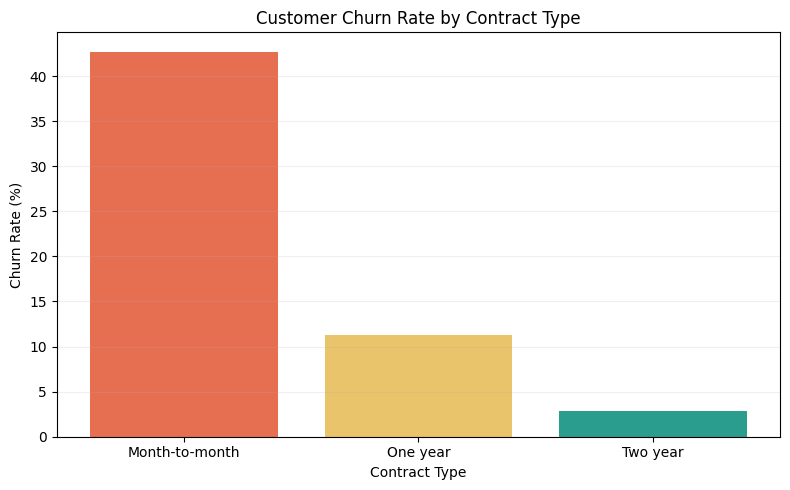

Graph generated successfully!


In [ ]:

import matplotlib.pyplot as plt

# Recalculate churn rate directly from the dataset
contract_analysis = (
    df.groupby("Contract")["Churn_Flag"]
    .agg(["count", "sum", "mean"])
)

# Rename columns
contract_analysis.columns = [
    "Total_Customers",
    "Churned_Customers",
    "Churn_Proportion"
]

# Convert proportion into percentage
contract_analysis["Churn_Rate"] = (
    contract_analysis["Churn_Proportion"] * 100
)

# Check the table
display(contract_analysis.round(2))

# Create the graph
plt.figure(figsize=(8, 5))

plt.bar(
    contract_analysis.index,
    contract_analysis["Churn_Rate"],
    color=["#E76F51", "#E9C46A", "#2A9D8F"]
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

print("Graph generated successfully!")


,Total_Customers,Churned_Customers,Churn_Proportion,Churn_Rate
Tenure_Group,,,,
0-12 months,2186,1037,0.47,47.44
13-24 months,1024,294,0.29,28.71
25-48 months,1594,325,0.20,20.39
49+ months,2239,213,0.10,9.51


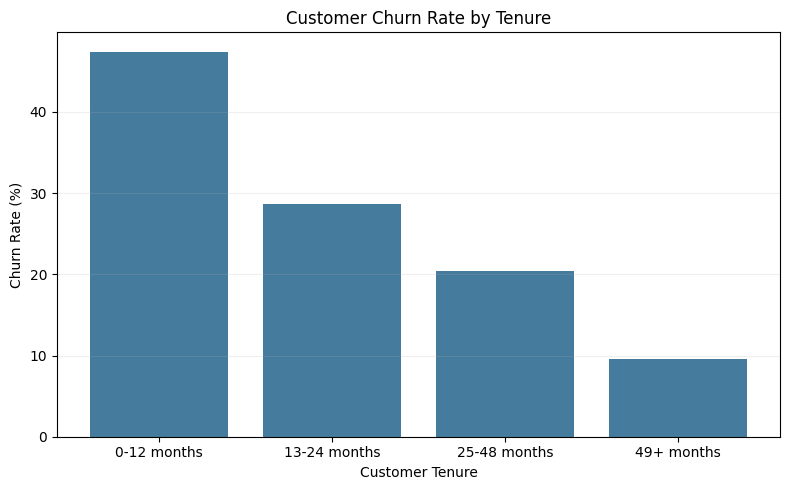

Tenure analysis completed successfully!


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Divide customers into tenure groups
df["Tenure_Group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 100],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49+ months"
    ]
)

# Step 2: Calculate churn statistics
tenure_analysis = df.groupby(
    "Tenure_Group", observed=True
)["Churn_Flag"].agg(["count", "sum", "mean"])

# Step 3: Rename columns
tenure_analysis.columns = [
    "Total_Customers",
    "Churned_Customers",
    "Churn_Proportion"
]

# Step 4: Calculate churn percentage
tenure_analysis["Churn_Rate"] = (
    tenure_analysis["Churn_Proportion"] * 100
)

# Step 5: Display results
display(tenure_analysis.round(2))

# Step 6: Create bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    tenure_analysis.index.astype(str),
    tenure_analysis["Churn_Rate"],
    color="#457B9D"
)

plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

print("Tenure analysis completed successfully!")


MONTHLY CHARGES ANALYSIS
------------------------
Churned customers: $74.44
Retained customers: $61.27


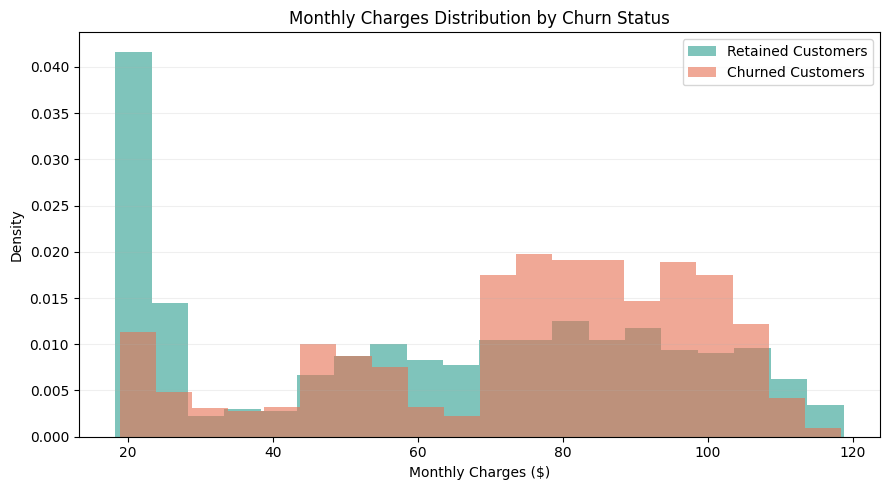

Monthly charges analysis completed!


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Separate churned and retained customers
churned = df[df["Churn"] == "Yes"]
retained = df[df["Churn"] == "No"]

# Step 2: Calculate average monthly charges
avg_churned = churned["MonthlyCharges"].mean()
avg_retained = retained["MonthlyCharges"].mean()

print("MONTHLY CHARGES ANALYSIS")
print("------------------------")
print(f"Churned customers: ${avg_churned:.2f}")
print(f"Retained customers: ${avg_retained:.2f}")

# Step 3: Plot monthly charge distributions
plt.figure(figsize=(9, 5))

plt.hist(
    retained["MonthlyCharges"],
    bins=20,
    alpha=0.6,
    density=True,
    label="Retained Customers",
    color="#2A9D8F"
)

plt.hist(
    churned["MonthlyCharges"],
    bins=20,
    alpha=0.6,
    density=True,
    label="Churned Customers",
    color="#E76F51"
)

# Step 4: Format the graph
plt.title("Monthly Charges Distribution by Churn Status")
plt.xlabel("Monthly Charges ($)")
plt.ylabel("Density")

plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

print("Monthly charges analysis completed!")


## 4. SQL-based business analysis

Load the prepared customer data into SQLite and query churn across key customer segments.


In [ ]:

import sqlite3
import pandas as pd

# Step 1: Create an SQLite database
conn = sqlite3.connect(":memory:")

# Step 2: Transfer our DataFrame into SQL
df.to_sql(
    "customers",
    conn,
    index=False,
    if_exists="replace"
)

# Step 3: Verify the database
query = "SELECT * FROM customers LIMIT 5;"

result = pd.read_sql_query(query, conn)

print("SQL database created successfully!")
display(result)


SQL database created successfully!


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_Flag,Tenure_Group
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,0-12 months
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,0,25-48 months
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,0-12 months
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0,25-48 months
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,0-12 months


In [ ]:

# SQL Query: Analyze churn by contract type

query = """
SELECT
    Contract,
    COUNT(*) AS Total_Customers,
    SUM(Churn_Flag) AS Churned_Customers,
    ROUND(
        AVG(Churn_Flag) * 100, 2
    ) AS Churn_Rate
FROM customers
GROUP BY Contract
ORDER BY Churn_Rate DESC;
"""

# Execute SQL query
result = pd.read_sql_query(query, conn)

# Display results
print("CUSTOMER CHURN BY CONTRACT TYPE")
display(result)


CUSTOMER CHURN BY CONTRACT TYPE


,Contract,Total_Customers,Churned_Customers,Churn_Rate
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


In [ ]:

# SQL Query: Customer churn by payment method

query = """
SELECT
    PaymentMethod,
    COUNT(*) AS Total_Customers,
    SUM(Churn_Flag) AS Churned_Customers,
    ROUND(
        AVG(Churn_Flag) * 100, 2
    ) AS Churn_Rate,
    ROUND(
        AVG(MonthlyCharges), 2
    ) AS Avg_Monthly_Charges
FROM customers
GROUP BY PaymentMethod
ORDER BY Churn_Rate DESC;
"""

# Execute SQL query
payment_analysis = pd.read_sql_query(query, conn)

# Display results
print("CUSTOMER CHURN BY PAYMENT METHOD")
display(payment_analysis)


CUSTOMER CHURN BY PAYMENT METHOD


,PaymentMethod,Total_Customers,Churned_Customers,Churn_Rate,Avg_Monthly_Charges
0,Electronic check,2365,1071,45.29,76.26
1,Mailed check,1612,308,19.11,43.92
2,Bank transfer (automatic),1544,258,16.71,67.19
3,Credit card (automatic),1522,232,15.24,66.51


In [ ]:

# SQL Query: Analyze churn by contract
# type and internet service

query = """
SELECT
    Contract,
    InternetService,
    COUNT(*) AS Total_Customers,
    SUM(Churn_Flag) AS Churned_Customers,
    ROUND(
        AVG(Churn_Flag) * 100, 2
    ) AS Churn_Rate,
    ROUND(
        AVG(MonthlyCharges), 2
    ) AS Avg_Monthly_Charges
FROM customers
GROUP BY Contract, InternetService
HAVING COUNT(*) >= 50
ORDER BY Churn_Rate DESC;
"""

# Execute the SQL query
segment_analysis = pd.read_sql_query(query, conn)

print("HIGH-CHURN CUSTOMER SEGMENTS")
display(segment_analysis)


HIGH-CHURN CUSTOMER SEGMENTS


,Contract,InternetService,Total_Customers,Churned_Customers,Churn_Rate,Avg_Monthly_Charges
0,Month-to-month,Fiber optic,2128,1162,54.61,87.02
1,Month-to-month,DSL,1223,394,32.22,50.22
2,One year,Fiber optic,539,104,19.29,98.78
3,Month-to-month,No,524,99,18.89,20.41
4,One year,DSL,570,53,9.30,61.40
5,Two year,Fiber optic,429,31,7.23,104.57
6,One year,No,364,9,2.47,20.82
7,Two year,DSL,628,12,1.91,70.46
8,Two year,No,638,5,0.78,21.78


## 5. Customer prioritization and business insights

Identify high-churn segments and summarize findings for retention planning.


In [ ]:

# CELL 15: Customer Retention Prioritization

import pandas as pd

# Step 1: Group customers by contract and internet service
priority_segments = df.groupby(
    ["Contract", "InternetService"]
).agg(
    Total_Customers=("customerID", "count"),
    Churned_Customers=("Churn_Flag", "sum"),
    Avg_Monthly_Charges=("MonthlyCharges", "mean")
).reset_index()

# Step 2: Calculate churn rate
priority_segments["Churn_Rate"] = (
    priority_segments["Churned_Customers"]
    / priority_segments["Total_Customers"]
) * 100

# Step 3: Calculate share of total churn
total_churned = df["Churn_Flag"].sum()

priority_segments["Share_of_Total_Churn"] = (
    priority_segments["Churned_Customers"]
    / total_churned
) * 100

# Step 4: Exclude very small customer segments
priority_segments = priority_segments[
    priority_segments["Total_Customers"] >= 50
].copy()

# Step 5: Rank by number of churned customers
priority_segments = priority_segments.sort_values(
    "Churned_Customers",
    ascending=False
)

# Step 6: Display results
display(priority_segments.round(2))

print("Customer prioritization analysis completed!")


,Contract,InternetService,Total_Customers,Churned_Customers,Avg_Monthly_Charges,Churn_Rate,Share_of_Total_Churn
1,Month-to-month,Fiber optic,2128,1162,87.02,54.61,62.17
0,Month-to-month,DSL,1223,394,50.22,32.22,21.08
4,One year,Fiber optic,539,104,98.78,19.29,5.56
2,Month-to-month,No,524,99,20.41,18.89,5.30
3,One year,DSL,570,53,61.40,9.30,2.84
7,Two year,Fiber optic,429,31,104.57,7.23,1.66
6,Two year,DSL,628,12,70.46,1.91,0.64
5,One year,No,364,9,20.82,2.47,0.48
8,Two year,No,638,5,21.78,0.78,0.27


Customer prioritization analysis completed!


In [ ]:

# CELL 16A: Business Insights Summary

import pandas as pd
from IPython.display import display, Markdown

# 1. Overall churn metrics
total_customers = len(df)
total_churned = int(df["Churn_Flag"].sum())
overall_churn = total_churned / total_customers * 100

# 2. Churn by contract type
contract_rates = (
    df.groupby("Contract")["Churn_Flag"]
    .mean() * 100
)

highest_contract = contract_rates.idxmax()
highest_contract_rate = contract_rates.max()

# 3. Churn by customer tenure
tenure_rates = (
    df.groupby(
        "Tenure_Group", observed=True
    )["Churn_Flag"].mean() * 100
)

highest_tenure = tenure_rates.idxmax()
highest_tenure_rate = tenure_rates.max()

# 4. Largest contributor to overall churn
top_segment = priority_segments.iloc[0]

# 5. Display a formatted business summary
display(Markdown(f"""
## Customer Churn — Business Insights Report

### Overall Customer KPIs

| Metric | Value |
|---|---:|
| Total Customers | {total_customers:,} |
| Churned Customers | {total_churned:,} |
| Overall Churn Rate | {overall_churn:.2f}% |

### Key Findings

| Analysis | Highest-Churn Category | Churn Rate |
|---|---|---:|
| Contract Type | {highest_contract} | {highest_contract_rate:.2f}% |
| Customer Tenure | {highest_tenure} | {highest_tenure_rate:.2f}% |

### Largest Contributor to Total Churn

| Metric | Value |
|---|---|
| Contract Type | {top_segment['Contract']} |
| Internet Service | {top_segment['InternetService']} |
| Churned Customers | {int(top_segment['Churned_Customers']):,} |
| Segment Churn Rate | {top_segment['Churn_Rate']:.2f}% |
| Share of Total Churn | {top_segment['Share_of_Total_Churn']:.2f}% |

"""))



## Customer Churn — Business Insights Report

### Overall Customer KPIs

| Metric | Value |
|---|---:|
| Total Customers | 7,043 |
| Churned Customers | 1,869 |
| Overall Churn Rate | 26.54% |

### Key Findings

| Analysis | Highest-Churn Category | Churn Rate |
|---|---|---:|
| Contract Type | Month-to-month | 42.71% |
| Customer Tenure | 0-12 months | 47.44% |

### Largest Contributor to Total Churn

| Metric | Value |
|---|---|
| Contract Type | Month-to-month |
| Internet Service | Fiber optic |
| Churned Customers | 1,162 |
| Segment Churn Rate | 54.61% |
| Share of Total Churn | 62.17% |



## 6. Business recommendations

Translate observed patterns into practical retention initiatives and document analytical limitations.



## Business Recommendations & Retention Strategy

### 1. Improve Early Customer Retention

**Finding:** Short-tenure customers exhibit higher observed churn.

**Recommendation:** Investigate onboarding experiences, provide proactive customer support and test early-stage retention initiatives.

**Business Objective:** Improve customer retention during the initial months of service.

### 2. Target High-Churn Contract Segments

**Finding:** Month-to-month customers have higher observed churn than customers on longer-term contracts.

**Recommendation:** Test loyalty benefits and suitable long-term subscription incentives for high-churn segments.

**Business Objective:** Reduce customer departures while maintaining profitability.

### 3. Evaluate Pricing and Service Quality

**Finding:** Customers who churned have higher average monthly charges than retained customers.

**Recommendation:** Investigate pricing concerns, perceived service value and support experiences among higher-billing customers.

**Business Objective:** Identify potential factors associated with customer dissatisfaction.

### 4. Implement Data-Driven Retention Experiments

**Recommendation:** Conduct controlled A/B tests before introducing retention programs at scale.

**Metrics to Monitor:**
- Customer churn rate
- Retention rate
- Campaign cost per retained customer
- Customer lifetime value
- Incremental revenue

### 5. Monitor Customer Segments Regularly

**Recommendation:** Build dashboards tracking churn by contract type, tenure, payment method and internet service.

**Business Objective:** Identify emerging churn patterns and support timely decisions.

---

### Analytical Limitations

- Observed relationships do not establish causation.
- The dataset does not contain results from retention interventions.
- Financial benefits of retention strategies cannot be established without additional assumptions and data.
- Predictive modelling and experimental validation could strengthen future analysis.

### Conclusion

The analysis identifies customer segments with elevated churn rates and substantial contributions to customer departures.

These findings provide a basis for investigating targeted retention initiatives and developing future predictive analytics models.


## 7. Export analysis outputs

Save the cleaned dataset and analytical tables for reuse.


In [ ]:

# CELL 17: Export Data and Analysis Results

import os
import pandas as pd

# Step 1: Create project folders
os.makedirs("outputs/data", exist_ok=True)
os.makedirs("outputs/analysis", exist_ok=True)

# Step 2: Export cleaned customer dataset
df.to_csv(
    "outputs/data/cleaned_customers.csv",
    index=False
)

# Step 3: Export contract churn analysis
contract_analysis.to_csv(
    "outputs/analysis/contract_analysis.csv"
)

# Step 4: Export tenure analysis
tenure_analysis.to_csv(
    "outputs/analysis/tenure_analysis.csv"
)

# Step 5: Export payment method analysis
payment_analysis.to_csv(
    "outputs/analysis/payment_analysis.csv",
    index=False
)

# Step 6: Export customer segmentation analysis
segment_analysis.to_csv(
    "outputs/analysis/segment_analysis.csv",
    index=False
)

# Step 7: Export priority customer segments
priority_segments.to_csv(
    "outputs/analysis/priority_segments.csv",
    index=False
)

# Step 8: Confirm exported files
for root, folders, files in os.walk("outputs"):
    for filename in files:
        print(os.path.join(root, filename))

print("\nAll project files exported successfully!")


outputs/analysis/tenure_analysis.csv
outputs/analysis/contract_analysis.csv
outputs/analysis/payment_analysis.csv
outputs/analysis/priority_segments.csv
outputs/analysis/segment_analysis.csv
outputs/data/cleaned_customers.csv

All project files exported successfully!


In [ ]:

from google.colab import files

files.download("outputs/data/cleaned_customers.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Predictive modelling — data preparation

Prepare features, target, train-test split and preprocessing pipeline. Preprocessing is fitted within each model pipeline to avoid leakage.


In [ ]:
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column names
print("\nColumns:")
print(df.columns.tolist())

# Check data types
print("\nData types:")
display(df.dtypes)

# Check missing values
print("\nMissing values:")
display(df.isnull().sum())

# Check target distribution
print("\nChurn distribution:")
display(df["Churn"].value_counts())

print("\nChurn percentage:")
display(
    df["Churn"].value_counts(normalize=True) * 100
)

Dataset shape: (7043, 23)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'Churn_Flag', 'Tenure_Group']

Data types:


,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



Missing values:


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Churn distribution:


,count
Churn,
No,5174
Yes,1869



Churn percentage:


,proportion
Churn,
No,73.463013
Yes,26.536987


In [ ]:
# Check missing TotalCharges records
missing_total = df[df["TotalCharges"].isnull()]

print("Missing TotalCharges:", len(missing_total))

# Verify whether these customers have zero tenure
display(
    missing_total[
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
    ]
)

# Replace missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify
print("\nRemaining missing values:")
print(df.isnull().sum().sum())

Missing TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN



Remaining missing values:
0


Separate features and target

- X: Variables used to predict churn.
- y: The actual churn outcome we want to predict.

In [ ]:
# Define target variable
y = df["Churn_Flag"]

# Remove target-related and identification columns
X = df.drop(
    columns=[
        "customerID",
        "Churn",
        "Churn_Flag",
        "Tenure_Group"
    ],
    errors="ignore"
)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Feature shape: (7043, 19)
Target shape: (7043,)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


Machine learning algorithms require numerical input.

However, our dataset contains both numerical and categorical variables.

In [ ]:
# Identify numerical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTotal numerical features:", len(numerical_features))
print("Total categorical features:", len(categorical_features))

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Total numerical features: 4
Total categorical features: 15


For this dataset, numerical features should include:
- SeniorCitizen
- tenure
- MonthlyCharges
- TotalCharges

Categorical features include gender, Partner, Dependents, PhoneService, MultipleLines, InternetService, OnlineSecurity, Contract, PaymentMethod and others.

**Split training and testing data**

80% Training data: Model learns patterns

20% Testing data: Evaluates performance



We'll use stratify=y to preserve approximately the same churn/non-churn proportion in both sets.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining churn distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training data: (5634, 19)
Testing data: (1409, 19)

Training churn distribution:
Churn_Flag
0    73.464679
1    26.535321
Name: proportion, dtype: float64

Testing churn distribution:
Churn_Flag
0    73.456352
1    26.543648
Name: proportion, dtype: float64


**Build the preprocessing pipeline**

We need different preprocessing for numerical and categorical variables.

**Numerical:**	Missing-value imputation + Standard Scaling

**Categorical:**	Missing-value imputation + One-Hot Encoding

In [ ]:
# Numerical preprocessing
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 9. Logistic Regression

Train a baseline classifier, evaluate its performance and interpret its coefficients.


Create and train the model

In [ ]:
# Create Logistic Regression pipeline

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


Predict customer churn

In [ ]:
# Predict churn classes
y_pred = logistic_model.predict(X_test)

# Predict churn probabilities
y_pred_proba = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

print("\nFirst 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(y_pred[:10])

print("\nFirst 10 churn probabilities:")
print(y_pred_proba[:10])

Predictions generated successfully!

First 10 actual values:
[0 0 0 0 0 0 0 0 0 1]

First 10 predicted values:
[0 1 0 0 0 1 0 0 0 0]

First 10 churn probabilities:
[0.04591993 0.68371345 0.05893985 0.40183529 0.02142426 0.60297803
 0.44762898 0.13033554 0.00280355 0.39473874]


Evaluate model performance

In [ ]:
# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

# Display results
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

display(results.round(4))

,Metric,Score
0,Accuracy,0.8055
1,Precision,0.6572
2,Recall,0.5588
3,F1 Score,0.6040
4,ROC-AUC,0.8421


Confusion matrix

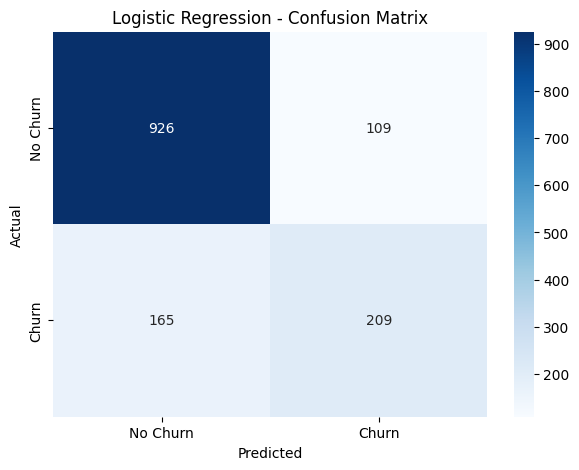

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

ROC Curve

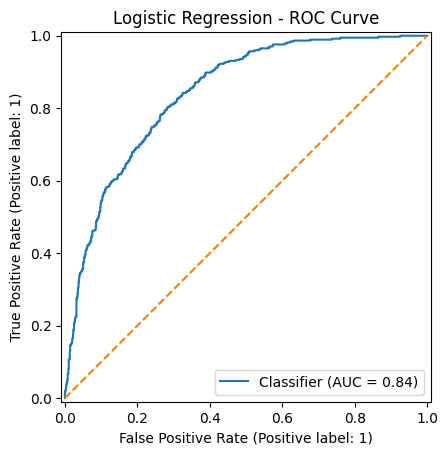

In [ ]:
RocCurveDisplay.from_predictions(
    y_test,
    y_pred_proba
)

plt.title("Logistic Regression - ROC Curve")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.show()

Extract feature coefficients

In [ ]:
# Get the trained preprocessing component
trained_preprocessor = logistic_model.named_steps["preprocessor"]

# Get transformed feature names
feature_names = trained_preprocessor.get_feature_names_out()

# Extract Logistic Regression coefficients
coefficients = logistic_model.named_steps["classifier"].coef_[0]

# Create coefficient dataframe
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by absolute coefficient magnitude
coefficient_df["Absolute_Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

display(coefficient_df.head(20))

,Feature,Coefficient,Absolute_Coefficient
1,num__tenure,-1.257539,1.257539
38,cat__Contract_Two year,-0.776594,0.776594
15,cat__InternetService_DSL,-0.648646,0.648646
16,cat__InternetService_Fiber optic,0.634195,0.634195
2,num__MonthlyCharges,-0.591863,0.591863
36,cat__Contract_Month-to-month,0.582883,0.582883
3,num__TotalCharges,0.536253,0.536253
39,cat__PaperlessBilling_No,-0.343227,0.343227
25,cat__DeviceProtection_No internet service,-0.300104,0.300104
17,cat__InternetService_No,-0.300104,0.300104


Coefficient visualization

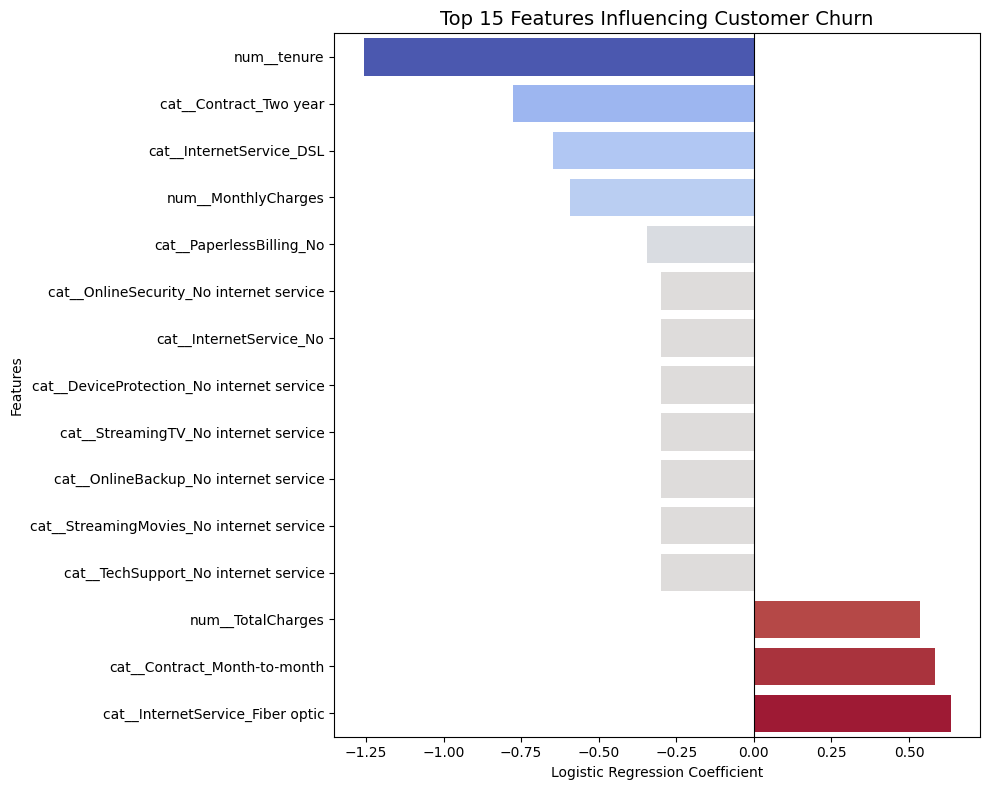

In [ ]:
# Select top 15 features by absolute coefficient
top_features = coefficient_df.head(15).copy()

# Sort for visualization
top_features = top_features.sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature",
    hue="Coefficient",
    palette="coolwarm",
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title(
    "Top 15 Features Influencing Customer Churn",
    fontsize=14
)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

## 10. Random Forest

Train a tree-based ensemble model and compare its performance with Logistic Regression.


Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [ ]:
# Create Random Forest pipeline

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            min_samples_split=5,
            min_samples_leaf=2,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        ))
    ]
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
# Predict customer churn
rf_pred = rf_model.predict(X_test)

# Predict churn probabilities
rf_pred_proba = rf_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
print(rf_pred[:10])

print("\nFirst 10 churn probabilities:")
print(rf_pred_proba[:10])

Predictions generated successfully!

First 10 predictions:
[0 1 0 0 0 1 1 0 0 1]

First 10 churn probabilities:
[0.0208427  0.80277783 0.11529588 0.45747687 0.04251916 0.77738353
 0.52067516 0.17144314 0.00231228 0.59232533]


In [ ]:
# Calculate evaluation metrics

rf_accuracy = accuracy_score(y_test, rf_pred)

rf_precision = precision_score(y_test, rf_pred)

rf_recall = recall_score(y_test, rf_pred)

rf_f1 = f1_score(y_test, rf_pred)

rf_roc_auc = roc_auc_score(y_test, rf_pred_proba)

# Display results

rf_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_roc_auc
    ]
})

display(rf_results.round(4))

,Metric,Score
0,Accuracy,0.7658
1,Precision,0.5445
2,Recall,0.7193
3,F1 Score,0.6198
4,ROC-AUC,0.8392


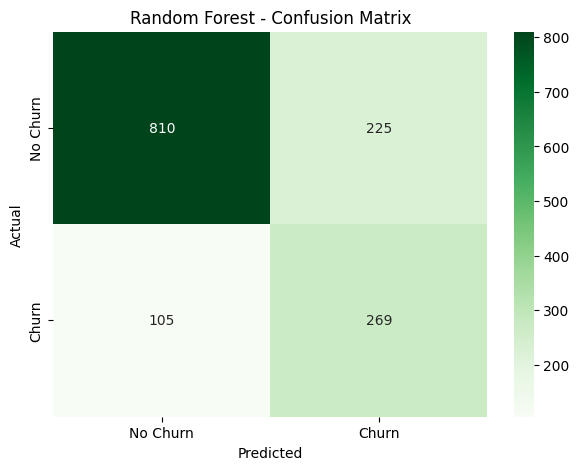

In [ ]:
cm_rf = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Random Forest - Confusion Matrix")

plt.show()

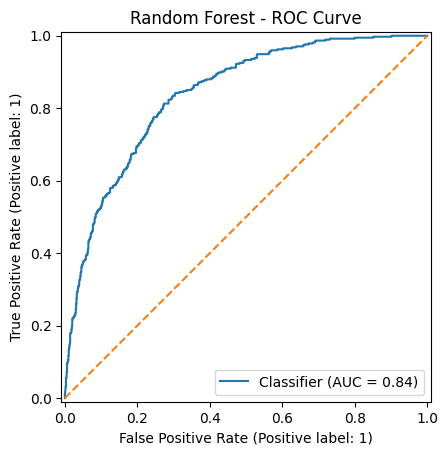

In [ ]:
RocCurveDisplay.from_predictions(
    y_test,
    rf_pred_proba
)

plt.title("Random Forest - ROC Curve")

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.show()

In [ ]:
# Compare Logistic Regression and Random Forest

model_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],

    "Logistic Regression": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ],

    "Random Forest": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_roc_auc
    ]
})

display(model_comparison.round(4))

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.8055,0.7658
1,Precision,0.6572,0.5445
2,Recall,0.5588,0.7193
3,F1 Score,0.6040,0.6198
4,ROC-AUC,0.8421,0.8392


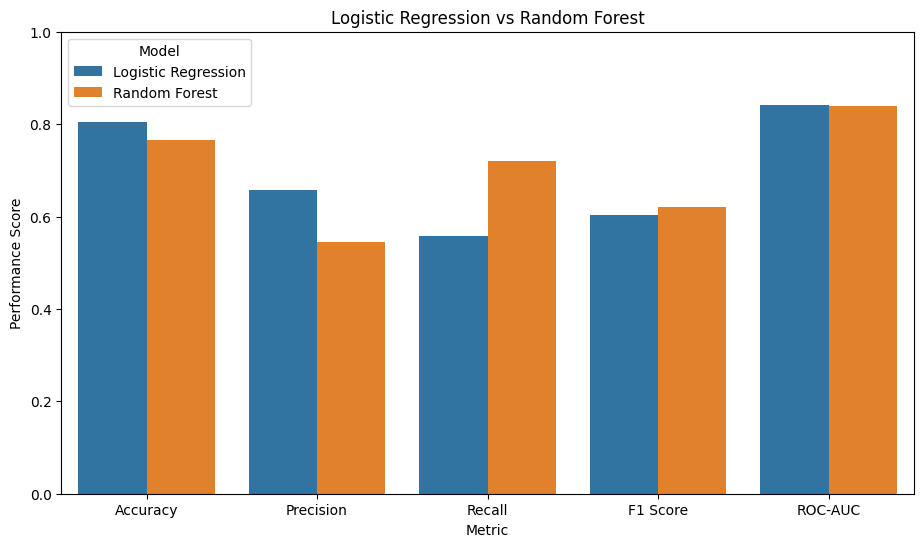

In [ ]:
comparison_plot = model_comparison.melt(
    id_vars="Metric",
    var_name="Model",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison_plot,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Logistic Regression vs Random Forest")

plt.ylim(0, 1)
plt.ylabel("Performance Score")

plt.show()

In [ ]:
# Extract trained preprocessing component

rf_preprocessor = rf_model.named_steps["preprocessor"]

# Extract transformed feature names

rf_feature_names = (
    rf_preprocessor.get_feature_names_out()
)

# Extract feature importance

rf_importances = (
    rf_model.named_steps["classifier"].feature_importances_
)

# Create dataframe

rf_importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importances
})

# Sort features

rf_importance_df = rf_importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(rf_importance_df.head(15))

,Feature,Importance
1,num__tenure,0.128540
36,cat__Contract_Month-to-month,0.114708
3,num__TotalCharges,0.099199
2,num__MonthlyCharges,0.072952
38,cat__Contract_Two year,0.063239
18,cat__OnlineSecurity_No,0.061725
16,cat__InternetService_Fiber optic,0.050373
27,cat__TechSupport_No,0.049837
43,cat__PaymentMethod_Electronic check,0.034826
21,cat__OnlineBackup_No,0.019565


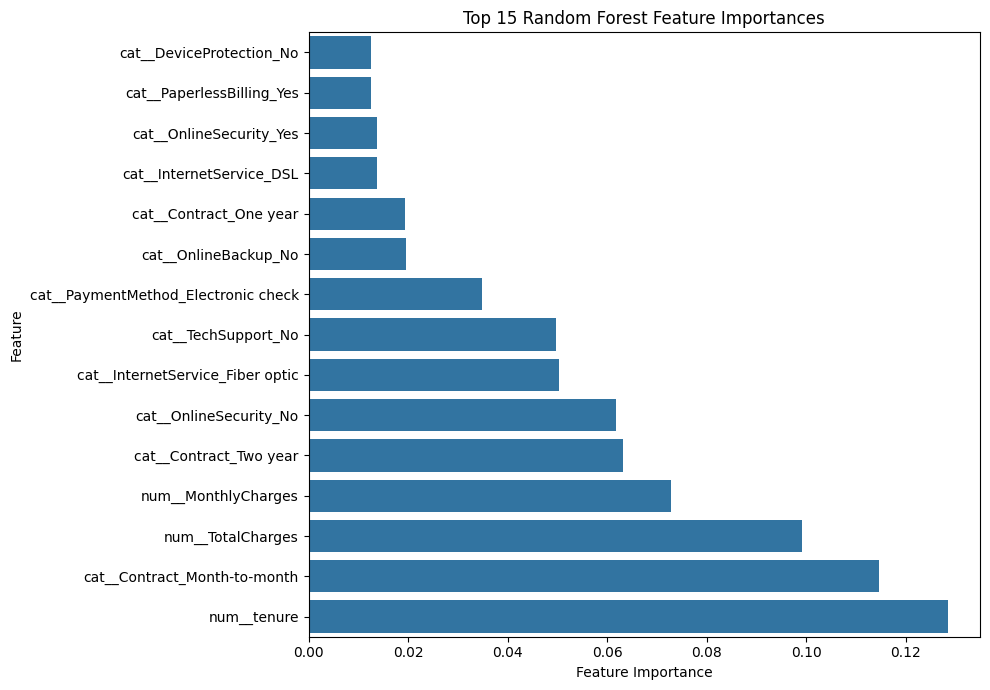

In [ ]:
top_rf_features = rf_importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_rf_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Random Forest Feature Importances")

plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## 11. Threshold optimization and final model selection

Compare thresholds on a validation split, select the model, then evaluate once on the held-out test set.


In [ ]:
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, f1_score

# Create validation split
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Train validation models
lr_val_model = clone(logistic_model)
rf_val_model = clone(rf_model)

lr_val_model.fit(X_train_new, y_train_new)
rf_val_model.fit(X_train_new, y_train_new)

# Generate probabilities
lr_probs = lr_val_model.predict_proba(X_val)[:, 1]
rf_probs = rf_val_model.predict_proba(X_val)[:, 1]

# Analyze thresholds
def analyze_thresholds(y_true, probabilities):
    results = []

    for t in np.arange(0.15, 0.76, 0.05):
        pred = (probabilities >= t).astype(int)

        results.append({
            "Threshold": round(t, 2),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred, zero_division=0)
        })

    return pd.DataFrame(results)

lr_thresholds = analyze_thresholds(y_val, lr_probs)
rf_thresholds = analyze_thresholds(y_val, rf_probs)

print("LOGISTIC REGRESSION")
display(lr_thresholds.round(3))

print("RANDOM FOREST")
display(rf_thresholds.round(3))

# Select highest precision subject to minimum 70% recall
def get_best_threshold(results):
    eligible = results[results["Recall"] >= 0.70]

    if len(eligible) == 0:
        return results.loc[results["F1"].idxmax()]

    return eligible.sort_values(
        ["Precision", "F1"],
        ascending=False
    ).iloc[0]

lr_best = get_best_threshold(lr_thresholds)
rf_best = get_best_threshold(rf_thresholds)

print("Best Logistic Regression threshold:")
display(lr_best)

print("Best Random Forest threshold:")
display(rf_best)

LOGISTIC REGRESSION


,Threshold,Precision,Recall,F1
0,0.15,0.429,0.896,0.581
1,0.20,0.465,0.856,0.603
2,0.25,0.512,0.803,0.625
3,0.30,0.545,0.756,0.633
4,0.35,0.579,0.709,0.638
5,0.40,0.617,0.669,0.642
6,0.45,0.659,0.602,0.629
7,0.50,0.694,0.545,0.610
8,0.55,0.732,0.502,0.595
9,0.60,0.728,0.368,0.489


RANDOM FOREST


,Threshold,Precision,Recall,F1
0,0.15,0.377,0.957,0.541
1,0.20,0.405,0.936,0.566
2,0.25,0.427,0.893,0.578
3,0.30,0.470,0.866,0.609
4,0.35,0.493,0.829,0.618
5,0.40,0.523,0.789,0.629
6,0.45,0.539,0.766,0.633
7,0.50,0.557,0.722,0.629
8,0.55,0.583,0.672,0.624
9,0.60,0.638,0.642,0.640


Best Logistic Regression threshold:


,4
Threshold,0.350000
Precision,0.579235
Recall,0.709030
F1,0.637594


Best Random Forest threshold:


,7
Threshold,0.500000
Precision,0.556701
Recall,0.722408
F1,0.628821


## 12. Customer churn probabilities and risk segmentation

Score customers, assign the existing Low, Medium and High risk bands, and export predictions.


In [ ]:
# Select final model using validation performance

candidates = {
    "Logistic Regression": (lr_best, logistic_model),
    "Random Forest": (rf_best, rf_model)
}

selected_name = max(
    candidates,
    key=lambda name: (
        candidates[name][0]["F1"],
        candidates[name][0]["Precision"]
    )
)

selected_result, selected_pipeline = candidates[selected_name]
final_threshold = float(selected_result["Threshold"])

# Retrain selected model on the complete training dataset
final_model = clone(selected_pipeline)
final_model.fit(X_train, y_train)

# Evaluate once on untouched test data
final_probabilities = final_model.predict_proba(X_test)[:, 1]

final_predictions = (
    final_probabilities >= final_threshold
).astype(int)

final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy_score(y_test, final_predictions),
        precision_score(y_test, final_predictions, zero_division=0),
        recall_score(y_test, final_predictions, zero_division=0),
        f1_score(y_test, final_predictions, zero_division=0),
        roc_auc_score(y_test, final_probabilities)
    ]
})

print("Selected Model:", selected_name)
print("Selected Threshold:", round(final_threshold, 2))
display(final_results.round(4))

print("\nClassification Report:")
print(classification_report(y_test, final_predictions))

Selected Model: Logistic Regression
Selected Threshold: 0.35


,Metric,Score
0,Accuracy,0.7644
1,Precision,0.5432
2,Recall,0.7059
3,F1 Score,0.6140
4,ROC-AUC,0.8421



Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.79      0.83      1035
           1       0.54      0.71      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409



## 13. Save model artifacts

Save the selected model, threshold, feature columns and evaluation outputs.


In [ ]:
# Predict churn probabilities for all customers

X_all = df.drop(
    columns=[
        "customerID", "Churn", "Churn_Flag", "Tenure_Group"
    ],
    errors="ignore"
)

all_probabilities = final_model.predict_proba(X_all)[:, 1]

# Create customer-level results
customer_results = df[["customerID"]].copy()

customer_results["Actual_Churn"] = df["Churn"]
customer_results["Churn_Probability"] = all_probabilities

customer_results["Risk_Category"] = pd.cut(
    all_probabilities,
    bins=[-0.001, 0.30, 0.60, 1.001],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

customer_results["Predicted_Churn"] = (
    all_probabilities >= final_threshold
).astype(int)

# Display results
display(
    customer_results.sort_values(
        "Churn_Probability",
        ascending=False
    ).head(20)
)

print("\nRisk distribution:")
display(customer_results["Risk_Category"].value_counts())

# Export predictions
customer_results.to_csv(
    "customer_churn_predictions.csv",
    index=False
)

,customerID,Actual_Churn,Churn_Probability,Risk_Category,Predicted_Churn
1976,9497-QCMMS,Yes,0.855494,High Risk,1
4800,9300-AGZNL,Yes,0.854411,High Risk,1
3380,5178-LMXOP,Yes,0.854280,High Risk,1
3749,4424-TKOPW,Yes,0.851391,High Risk,1
6368,2720-WGKHP,Yes,0.850569,High Risk,1
5989,5567-WSELE,Yes,0.848054,High Risk,1
1410,7024-OHCCK,Yes,0.847839,High Risk,1
3159,5150-ITWWB,No,0.846503,High Risk,1
2208,7216-EWTRS,Yes,0.844837,High Risk,1
997,1374-DMZUI,Yes,0.841069,High Risk,1



Risk distribution:


,count
Risk_Category,
Low Risk,4371
Medium Risk,1633
High Risk,1039


## 14. Download project outputs

Download the generated prediction and evaluation files from Google Colab.


In [ ]:
import joblib
import json

# Save trained model and metadata
artifacts = {
    "model": final_model,
    "model_name": selected_name,
    "threshold": final_threshold,
    "feature_columns": X.columns.tolist(),
    "risk_thresholds": {
        "low": 0.30,
        "medium": 0.60
    }
}

joblib.dump(artifacts, "churn_model.joblib")

# Save model evaluation
final_results.to_csv(
    "final_model_evaluation.csv",
    index=False
)

# Save customer predictions
customer_results.to_csv(
    "customer_churn_predictions.csv",
    index=False
)

print("Project artifacts saved successfully!")

print("\nFiles created:")
print("- churn_model.joblib")
print("- final_model_evaluation.csv")
print("- customer_churn_predictions.csv")

Project artifacts saved successfully!

Files created:
- churn_model.joblib
- final_model_evaluation.csv
- customer_churn_predictions.csv


In [ ]:

from google.colab import files

files.download("customer_churn_predictions.csv")
files.download("final_model_evaluation.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>